In [1]:
%pip -q install rdkit requests pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 20.4 MB/s eta 0:00:00


Retrieve and check the parent structure

,Parent_ID,PubChem_CID,Source_SMILES,RDKit_canonical_SMILES,Molecular_formula,InChIKey,RDKit_version,Retrieved_UTC,Source_URL,Automated_checks,Manual_literature_review
0,TRYPTANTHRIN_PARENT,73549,C1=CC=C2C(=C1)C(=O)N3C4=CC=CC=C4C(=O)C3=N2,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,C15H8N2O2,VQQVWGVXDIPORV-UHFFFAOYSA-N,2026.09.1,20261020T034709468999Z,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,PASS,PENDING


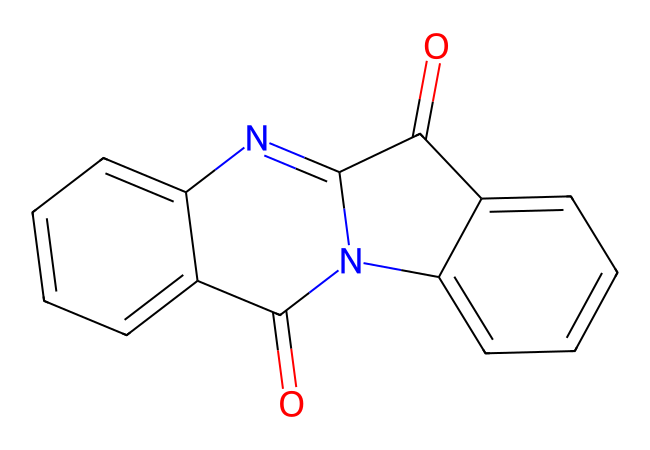

Automated structure checks: PASS

RDKit canonical SMILES: O=C1c2ccccc2-n2c1nc1ccccc1c2=O
Molecular formula: C15H8N2O2
InChIKey: VQQVWGVXDIPORV-UHFFFAOYSA-N

Manual comparison with a published structure remains pending.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json

import pandas as pd
import requests
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display

# Separate output folder for each run.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output_dir = Path("parent_verification") / run_id
output_dir.mkdir(parents=True, exist_ok=False)

# PubChem identifies tryptanthrin as CID 73549.
cid = 73549
url = (
    f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}"
    "/property/CanonicalSMILES,InChIKey,MolecularFormula/JSON"
)

response = requests.get(url, timeout=60)
response.raise_for_status()
source_data = response.json()

# Preserve the original downloaded record.
(output_dir / "pubchem_source.json").write_text(
    json.dumps(source_data, indent=2),
    encoding="utf-8"
)

record = source_data["PropertyTable"]["Properties"][0]
assert record["CID"] == cid, "Unexpected compound ID."

# Support both newer and older PubChem field names.
source_smiles = (
    record.get("ConnectivitySMILES")
    or record.get("CanonicalSMILES")
    or record.get("SMILES")
)
assert source_smiles, f"SMILES missing. Returned fields: {list(record)}"

mol = Chem.MolFromSmiles(source_smiles)
assert mol is not None, "RDKit could not read the structure."
Chem.SanitizeMol(mol)

canonical_smiles = Chem.MolToSmiles(
    mol, canonical=True, isomericSmiles=True
)
formula = rdMolDescriptors.CalcMolFormula(mol)
inchikey = Chem.MolToInchiKey(mol)

assert formula == record["MolecularFormula"] == "C15H8N2O2", \
    "Molecular formula mismatch."
assert inchikey == record["InChIKey"], "InChIKey mismatch."
assert len(Chem.GetMolFrags(mol)) == 1, \
    "Unexpected disconnected structure."
assert Chem.GetFormalCharge(mol) == 0, \
    "Unexpected formal charge."

# Check that the saved SMILES reconstructs the same identity.
reloaded = Chem.MolFromSmiles(canonical_smiles)
assert reloaded is not None
assert Chem.MolToInchiKey(reloaded) == inchikey

result = {
    "Parent_ID": "TRYPTANTHRIN_PARENT",
    "PubChem_CID": cid,
    "Source_SMILES": source_smiles,
    "RDKit_canonical_SMILES": canonical_smiles,
    "Molecular_formula": formula,
    "InChIKey": inchikey,
    "RDKit_version": rdBase.rdkitVersion,
    "Retrieved_UTC": run_id,
    "Source_URL": url,
    "Automated_checks": "PASS",
    "Manual_literature_review": "PENDING"
}

table = pd.DataFrame([result])
table.to_csv(output_dir / "parent_verification.csv", index=False)

Chem.MolToMolFile(mol, str(output_dir / "parent.mol"))
structure_image = Draw.MolToImage(mol, size=(650, 450))
structure_image.save(output_dir / "parent_structure.png")

display(table)
display(structure_image)

print("Automated structure checks: PASS")
print("\nRDKit canonical SMILES:", canonical_smiles)
print("Molecular formula:", formula)
print("InChIKey:", inchikey)
print("\nManual comparison with a published structure remains pending.")

Download your outputs

In [3]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    f"/content/parent_verification_{run_id}",
    "zip",
    root_dir=str(output_dir)
)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

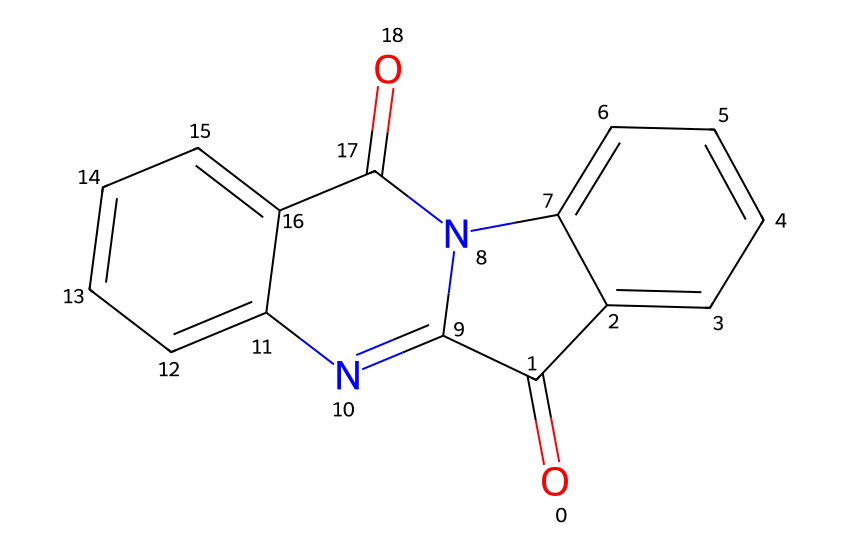

In [4]:
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

parent_smiles = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(parent_smiles)
assert parent is not None, "Parent structure could not be read."

drawer = rdMolDraw2D.MolDraw2DSVG(850, 550)
drawer.drawOptions().addAtomIndices = True
drawer.DrawMolecule(parent)
drawer.FinishDrawing()

display(SVG(drawer.GetDrawingText()))

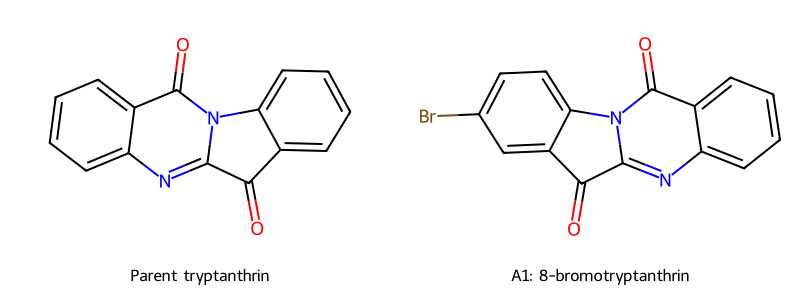

Analog SMILES: O=C1c2cc(Br)ccc2-n2c1nc1ccccc1c2=O
Formula: C15H7BrN2O2
Structure and scaffold checks: PASS


In [5]:
from rdkit import Chem
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display

# Keep this exact SMILES so the atom-index mapping stays consistent.
parent_smiles = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(parent_smiles)
assert parent is not None

c8_index = 4
site = parent.GetAtomWithIdx(c8_index)

assert site.GetSymbol() == "C"
assert site.GetIsAromatic()
assert site.GetTotalNumHs() == 1, "Expected one replaceable hydrogen."

# Attach Br. RDKit updates the implicit hydrogen during sanitization.
editable = Chem.RWMol(parent)
br_index = editable.AddAtom(Chem.Atom("Br"))
editable.AddBond(c8_index, br_index, Chem.BondType.SINGLE)

analog = editable.GetMol()
Chem.SanitizeMol(analog)

assert rdMolDescriptors.CalcMolFormula(analog) == "C15H7BrN2O2"
assert analog.HasSubstructMatch(parent), "Parent scaffold check failed."

analog_smiles = Chem.MolToSmiles(analog, canonical=True)

display(Draw.MolsToGridImage(
    [parent, analog],
    legends=["Parent tryptanthrin", "A1: 8-bromotryptanthrin"],
    molsPerRow=2,
    subImgSize=(400, 300)
))

print("Analog SMILES:", analog_smiles)
print("Formula:", rdMolDescriptors.CalcMolFormula(analog))
print("Structure and scaffold checks: PASS")

,Reference_ID,Source_compound_ID,SMILES,Modified_site,Substituent,Modification_type,Molecular_formula,Source_DOI,Source_location,Status,Automated_checks
0,Gao2021_A1,A1,O=C1c2cc(Br)ccc2-n2c1nc1ccccc1c2=O,C-8,Br,Ring hydrogen substitution,C15H7BrN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
1,Gao2021_A2,A2,O=C1c2cc(I)ccc2-n2c1nc1ccccc1c2=O,C-8,I,Ring hydrogen substitution,C15H7IN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
2,Gao2021_A3,A3,O=C1c2cc(Cl)ccc2-n2c1nc1ccccc1c2=O,C-8,Cl,Ring hydrogen substitution,C15H7ClN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
3,Gao2021_A4,A4,O=C1c2cc(F)ccc2-n2c1nc1ccccc1c2=O,C-8,F,Ring hydrogen substitution,C15H7FN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
4,Gao2021_A5,A5,Cc1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,C-8,CH3,Ring hydrogen substitution,C16H10N2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
5,Gao2021_A6,A6,O=C1c2cc([N+](=O)[O-])ccc2-n2c1nc1ccccc1c2=O,C-8,NO2,Ring hydrogen substitution,C15H7N3O4,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
6,Gao2021_A7,A7,Nc1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,C-8,NH2,Ring hydrogen substitution,C15H9N3O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS


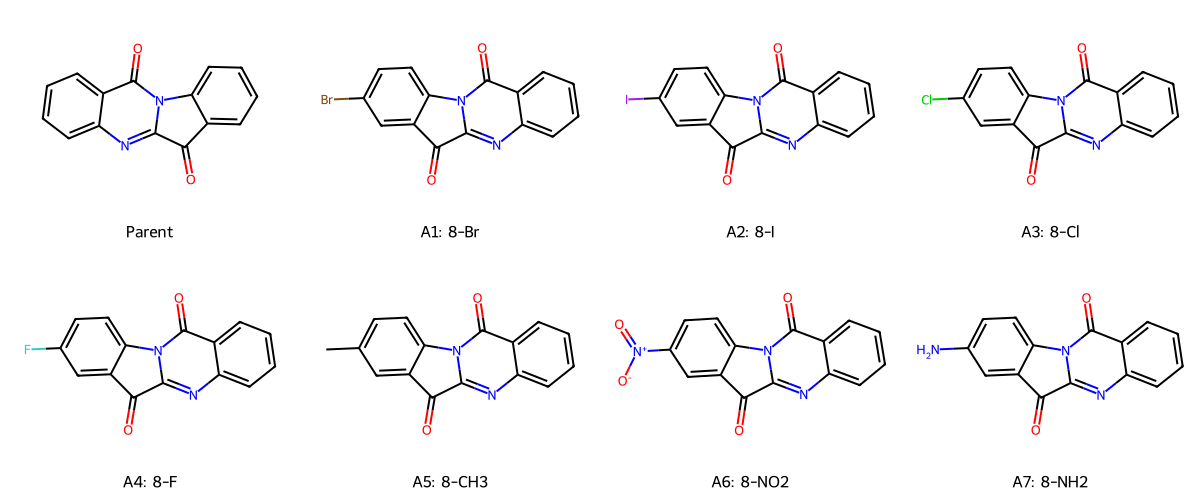

Generated: 7 reference derivatives
Formula, scaffold, connectivity and uniqueness checks: PASS


In [6]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display

# Atom index 4 maps to C-8 ONLY for this exact parent SMILES.
parent_smiles = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(parent_smiles)
assert parent is not None
c8_index = 4

# First atom in each fragment is the atom attached to C-8.
rules = [
    ("A1", "Br",  "Br",            "C15H7BrN2O2"),
    ("A2", "I",   "I",             "C15H7IN2O2"),
    ("A3", "Cl",  "Cl",            "C15H7ClN2O2"),
    ("A4", "F",   "F",             "C15H7FN2O2"),
    ("A5", "CH3", "C",             "C16H10N2O2"),
    ("A6", "NO2", "[N+](=O)[O-]",  "C15H7N3O4"),
    ("A7", "NH2", "N",             "C15H9N3O2"),
]

molecules, rows = [], []

for compound_id, substituent, fragment_smiles, expected_formula in rules:
    fragment = Chem.MolFromSmiles(fragment_smiles)
    assert fragment is not None

    combined = Chem.CombineMols(parent, fragment)
    editable = Chem.RWMol(combined)

    # Fragment atom 0 follows the last parent atom.
    attachment_index = parent.GetNumAtoms()
    editable.AddBond(
        c8_index, attachment_index, Chem.BondType.SINGLE
    )

    analog = editable.GetMol()
    Chem.SanitizeMol(analog)

    formula = rdMolDescriptors.CalcMolFormula(analog)
    assert formula == expected_formula, f"{compound_id}: formula mismatch"
    assert analog.HasSubstructMatch(parent), \
        f"{compound_id}: scaffold mismatch"
    assert len(Chem.GetMolFrags(analog)) == 1
    assert Chem.GetFormalCharge(analog) == 0

    smiles = Chem.MolToSmiles(analog, canonical=True)
    molecules.append(analog)

    rows.append({
        "Reference_ID": f"Gao2021_{compound_id}",
        "Source_compound_ID": compound_id,
        "SMILES": smiles,
        "Modified_site": "C-8",
        "Substituent": substituent,
        "Modification_type": "Ring hydrogen substitution",
        "Molecular_formula": formula,
        "Source_DOI": "10.3390/biomedicines9111527",
        "Source_location": "Figure 1B, page 2",
        "Status": "Published reference reconstruction",
        "Automated_checks": "PASS",
    })

reference_library = pd.DataFrame(rows)
assert reference_library["SMILES"].is_unique, "Duplicate structures found."

display(reference_library)
display(Draw.MolsToGridImage(
    [parent] + molecules,
    legends=["Parent"] + [
        f"{r[0]}: 8-{r[1]}" for r in rules
    ],
    molsPerRow=4,
    subImgSize=(300, 250)
))

print(f"Generated: {len(reference_library)} reference derivatives")
print("Formula, scaffold, connectivity and uniqueness checks: PASS")

In [7]:
from google.colab import files

filename = "Gao2021_C8_reference_batch.csv"
reference_library.to_csv(filename, index=False)
files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Reference verification — Gao et al. (2021)

DOI: 10.3390/biomedicines9111527

A1–A7 substitution identities and molecular formulas were checked
against Figure 1B and supplementary pages S4–S7.

C-8 substituents:
A1: Br
A2: I
A3: Cl
A4: F
A5: CH3
A6: NO2
A7: NH2

The generated batch contains seven unique structures.
Formula, connectivity and parent-scaffold checks passed.

These are reconstructions of published reference compounds.

In [8]:
import pandas as pd
from google.colab import files

rules_table = pd.DataFrame([
    ("Gao2021_A1", "Br",  "Br"),
    ("Gao2021_A2", "I",   "I"),
    ("Gao2021_A3", "Cl",  "Cl"),
    ("Gao2021_A4", "F",   "F"),
    ("Gao2021_A5", "CH3", "C"),
    ("Gao2021_A6", "NO2", "[N+](=O)[O-]"),
    ("Gao2021_A7", "NH2", "N"),
], columns=["Reference_ID", "Substituent", "Fragment_SMILES"])

rules_table["Modified_site"] = "C-8"
rules_table["Parent_SMILES"] = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
rules_table["Parent_atom_index"] = 4
rules_table["Fragment_attachment_index"] = 0
rules_table["Source_DOI"] = "10.3390/biomedicines9111527"
rules_table["Evidence"] = "Figure 1B; supplement S4-S7"
rules_table["Scope"] = "Published reference reconstruction"

assert rules_table["Reference_ID"].is_unique
assert len(rules_table) == 7

filename = "Gao2021_C8_modification_rules.csv"
rules_table.to_csv(filename, index=False)

display(rules_table)
files.download(filename)

,Reference_ID,Substituent,Fragment_SMILES,Modified_site,Parent_SMILES,Parent_atom_index,Fragment_attachment_index,Source_DOI,Evidence,Scope
0,Gao2021_A1,Br,Br,C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction
1,Gao2021_A2,I,I,C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction
2,Gao2021_A3,Cl,Cl,C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction
3,Gao2021_A4,F,F,C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction
4,Gao2021_A5,CH3,C,C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction
5,Gao2021_A6,NO2,[N+](=O)[O-],C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction
6,Gao2021_A7,NH2,N,C-8,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,4,0,10.3390/biomedicines9111527,Figure 1B; supplement S4-S7,Published reference reconstruction


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from pathlib import Path
import pandas as pd
from rdkit import Chem

rules_path = Path("Gao2021_C8_modification_rules.csv")
assert rules_path.exists(), "Run the previous rules-table cell first."

loaded_rules = pd.read_csv(rules_path)

required_columns = [
    "Reference_ID", "Fragment_SMILES", "Modified_site",
    "Parent_SMILES", "Parent_atom_index",
    "Fragment_attachment_index"
]
assert set(required_columns).issubset(loaded_rules.columns)
assert len(loaded_rules) == 7
assert loaded_rules["Reference_ID"].is_unique

for _, rule in loaded_rules.iterrows():
    parent = Chem.MolFromSmiles(rule["Parent_SMILES"])
    fragment = Chem.MolFromSmiles(rule["Fragment_SMILES"])

    assert parent is not None
    assert fragment is not None

    parent_index = int(rule["Parent_atom_index"])
    fragment_index = int(rule["Fragment_attachment_index"])

    assert 0 <= parent_index < parent.GetNumAtoms()
    assert 0 <= fragment_index < fragment.GetNumAtoms()
    assert parent.GetAtomWithIdx(parent_index).GetTotalNumHs() == 1

print("Rules file loaded successfully: 7 rules passed input checks.")


Rules file loaded successfully: 7 rules passed input checks.


In [10]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
from rdkit import Chem, rdBase

assert "loaded_rules" in globals(), "Run the rules-loading cell first."

reference = pd.read_csv("Gao2021_C8_reference_batch.csv")
expected = reference.set_index("Reference_ID")["SMILES"].to_dict()

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
out = Path("reference_batch_runs") / run_id
out.mkdir(parents=True, exist_ok=False)

raw_rows, audit_rows = [], []

for _, rule in loaded_rules.iterrows():
    ref_id = rule["Reference_ID"]
    record = rule.to_dict()
    record["SMILES"] = ""
    record["RDKit_version"] = rdBase.rdkitVersion

    try:
        parent = Chem.MolFromSmiles(rule["Parent_SMILES"])
        fragment = Chem.MolFromSmiles(rule["Fragment_SMILES"])
        if parent is None or fragment is None:
            raise ValueError("Parent or fragment could not be parsed.")

        parent_index = int(rule["Parent_atom_index"])
        fragment_index = int(rule["Fragment_attachment_index"])

        editable = Chem.RWMol(Chem.CombineMols(parent, fragment))
        editable.AddBond(
            parent_index,
            parent.GetNumAtoms() + fragment_index,
            Chem.BondType.SINGLE
        )

        analog = editable.GetMol()
        Chem.SanitizeMol(analog)
        smiles = Chem.MolToSmiles(analog, canonical=True)
        record["SMILES"] = smiles

        if len(Chem.GetMolFrags(analog)) != 1:
            raise ValueError("Disconnected structure.")
        if not analog.HasSubstructMatch(parent):
            raise ValueError("Parent scaffold check failed.")

        # Regression check against the previously reviewed reference batch.
        expected_mol = Chem.MolFromSmiles(expected[ref_id])
        expected_smiles = Chem.MolToSmiles(expected_mol, canonical=True)
        if smiles != expected_smiles:
            raise ValueError("Does not match earlier reference structure.")

        status, reason = "PASS", ""

    except Exception as error:
        status, reason = "FAILED", str(error)

    record["Validation_status"] = status
    raw_rows.append(record)
    audit_rows.append({
        "Reference_ID": ref_id,
        "Validation_status": status,
        "Reason": reason
    })

raw = pd.DataFrame(raw_rows)
audit = pd.DataFrame(audit_rows)

valid = raw.loc[raw["Validation_status"] == "PASS"].copy()
duplicates = valid.duplicated("SMILES", keep="first")
duplicate_ids = valid.loc[duplicates, "Reference_ID"]

audit.loc[
    audit["Reference_ID"].isin(duplicate_ids),
    ["Validation_status", "Reason"]
] = ["DUPLICATE", "Same canonical SMILES as an earlier retained row."]

clean = valid.loc[~duplicates].copy()

summary = pd.DataFrame([{
    "Attempted": len(raw),
    "Failed": int((audit["Validation_status"] == "FAILED").sum()),
    "Duplicates": int((audit["Validation_status"] == "DUPLICATE").sum()),
    "Retained": len(clean)
}])

assert (
    summary["Attempted"].iloc[0]
    == summary[["Failed", "Duplicates", "Retained"]].sum(axis=1).iloc[0]
)

raw.to_csv(out / "reference_batch_raw.csv", index=False)
clean.to_csv(out / "reference_batch_clean.csv", index=False)
audit.to_csv(out / "reference_batch_audit.csv", index=False)
summary.to_csv(out / "reference_batch_statistics.csv", index=False)

display(summary)
display(audit)
print("Saved outputs:", out)

,Attempted,Failed,Duplicates,Retained
0,7,0,0,7


,Reference_ID,Validation_status,Reason
0,Gao2021_A1,PASS,
1,Gao2021_A2,PASS,
2,Gao2021_A3,PASS,
3,Gao2021_A4,PASS,
4,Gao2021_A5,PASS,
5,Gao2021_A6,PASS,
6,Gao2021_A7,PASS,


Saved outputs: reference_batch_runs/20261020T040725515795Z


In [11]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    f"/content/reference_batch_{run_id}",
    "zip",
    root_dir=str(out)
)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Attempted,Failed,Duplicates,Retained
0,9,0,0,9


,Reference_ID,Validation_status,Reason
0,Gao2021_A1,PASS,
1,Gao2021_A2,PASS,
2,Gao2021_A3,PASS,
3,Gao2021_A4,PASS,
4,Gao2021_A5,PASS,
5,Gao2021_A6,PASS,
6,Gao2021_A7,PASS,
7,Gao2021_A8,PASS,
8,Gao2021_A9,PASS,


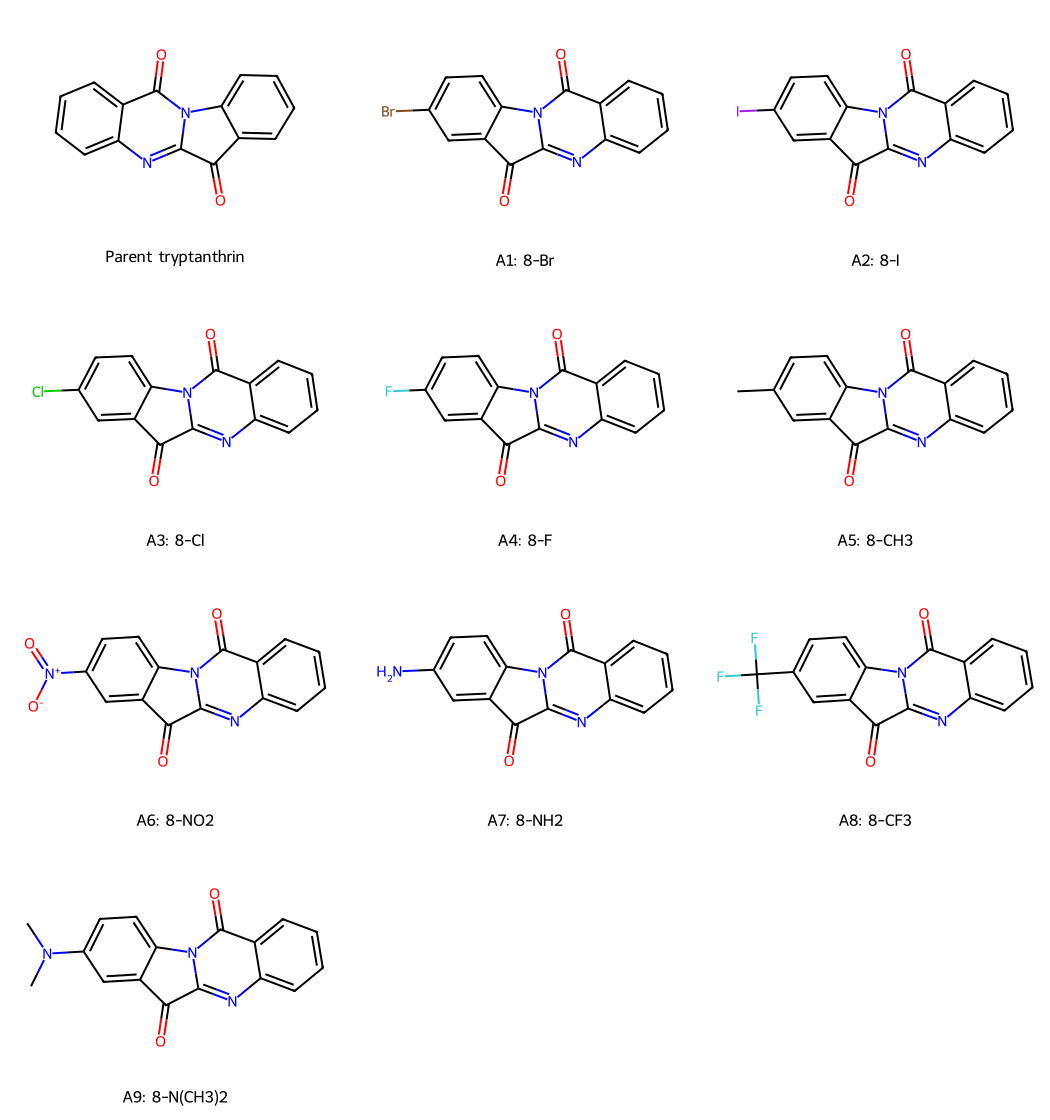

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil

import pandas as pd
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display
from google.colab import files

# Exact parent SMILES: atom index 4 corresponds to chemical C-8.
PARENT_SMILES = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
C8_INDEX = 4
DOI = "10.3390/biomedicines9111527"

parent = Chem.MolFromSmiles(PARENT_SMILES)
assert parent is not None
assert Chem.MolToInchiKey(parent) == \
    "VQQVWGVXDIPORV-UHFFFAOYSA-N"
assert parent.GetAtomWithIdx(C8_INDEX).GetTotalNumHs() == 1

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
out = Path("Gao2021_C8_reference_runs") / run_id
out.mkdir(parents=True, exist_ok=False)

# Fragment atom 0 is always the attachment atom.
rules = pd.DataFrame([
    ("A1", "Br",      "Br",            "C15H7BrN2O2", "S4-S5"),
    ("A2", "I",       "I",             "C15H7IN2O2",  "S5"),
    ("A3", "Cl",      "Cl",            "C15H7ClN2O2", "S5"),
    ("A4", "F",       "F",             "C15H7FN2O2",  "S5-S6"),
    ("A5", "CH3",     "C",             "C16H10N2O2",  "S6"),
    ("A6", "NO2",     "[N+](=O)[O-]",  "C15H7N3O4",   "S6"),
    ("A7", "NH2",     "N",             "C15H9N3O2",   "S7"),
    ("A8", "CF3",     "C(F)(F)F",      "C16H7F3N2O2", "S7"),
    ("A9", "N(CH3)2", "N(C)C",         "C17H13N3O2",  "S8"),
], columns=[
    "Source_compound_ID", "Substituent", "Fragment_SMILES",
    "Expected_formula", "Supplement_pages"
])

rules["Reference_ID"] = "Gao2021_" + rules["Source_compound_ID"]
rules["Modified_site"] = "C-8"
rules["Parent_SMILES"] = PARENT_SMILES
rules["Parent_atom_index"] = C8_INDEX
rules["Fragment_attachment_index"] = 0
rules["Source_DOI"] = DOI
rules["Source_location"] = "Figure 1B; supplementary chemical names"
rules["Scope"] = "Published reference reconstruction"

assert rules["Reference_ID"].is_unique
rules.to_csv(out / "modification_rules.csv", index=False)

raw_rows, audit_rows = [], []
retained_molecules, legends = [], []
seen = {}

for _, rule in rules.iterrows():
    record = rule.to_dict()
    record.update({
        "SMILES": "",
        "Molecular_formula": "",
        "InChIKey": "",
        "RDKit_version": rdBase.rdkitVersion,
        "Validation_status": "FAILED",
        "Reason": ""
    })

    try:
        fragment = Chem.MolFromSmiles(rule["Fragment_SMILES"])
        if fragment is None:
            raise ValueError("Fragment could not be parsed.")

        editable = Chem.RWMol(Chem.CombineMols(parent, fragment))
        editable.AddBond(
            C8_INDEX,
            parent.GetNumAtoms(),
            Chem.BondType.SINGLE
        )

        analog = editable.GetMol()
        Chem.SanitizeMol(analog)

        smiles = Chem.MolToSmiles(analog, canonical=True)
        formula = rdMolDescriptors.CalcMolFormula(analog)

        record["SMILES"] = smiles
        record["Molecular_formula"] = formula
        record["InChIKey"] = Chem.MolToInchiKey(analog)

        if formula != rule["Expected_formula"]:
            raise ValueError("Unexpected molecular formula.")
        if len(Chem.GetMolFrags(analog)) != 1:
            raise ValueError("Disconnected structure.")
        if Chem.GetFormalCharge(analog) != 0:
            raise ValueError("Unexpected net formal charge.")
        if not analog.HasSubstructMatch(parent):
            raise ValueError("Parent scaffold not retained.")

        # Confirm the intended fragment was attached at the specified atom.
        bond = analog.GetBondBetweenAtoms(
            C8_INDEX, parent.GetNumAtoms()
        )
        if bond is None or bond.GetBondType() != Chem.BondType.SINGLE:
            raise ValueError("Attachment bond check failed.")

        if smiles in seen:
            record["Validation_status"] = "DUPLICATE"
            record["Reason"] = f"Same structure as {seen[smiles]}"
        else:
            seen[smiles] = rule["Reference_ID"]
            record["Validation_status"] = "PASS"
            retained_molecules.append(analog)
            legends.append(
                f'{rule["Source_compound_ID"]}: 8-{rule["Substituent"]}'
            )

    except Exception as error:
        record["Reason"] = str(error)

    raw_rows.append(record)
    audit_rows.append({
        "Reference_ID": record["Reference_ID"],
        "Validation_status": record["Validation_status"],
        "Reason": record["Reason"]
    })

raw = pd.DataFrame(raw_rows)
audit = pd.DataFrame(audit_rows)
clean = raw.loc[raw["Validation_status"] == "PASS"].copy()

summary = pd.DataFrame([{
    "Attempted": len(raw),
    "Failed": int((audit["Validation_status"] == "FAILED").sum()),
    "Duplicates": int((audit["Validation_status"] == "DUPLICATE").sum()),
    "Retained": len(clean)
}])

assert len(raw) == (
    int(summary.loc[0, "Failed"])
    + int(summary.loc[0, "Duplicates"])
    + int(summary.loc[0, "Retained"])
)

raw.to_csv(out / "reference_library_raw.csv", index=False)
clean.to_csv(out / "reference_library_clean.csv", index=False)
audit.to_csv(out / "validation_audit.csv", index=False)
summary.to_csv(out / "library_statistics.csv", index=False)

# Save the unchanged parent separately.
pd.DataFrame([{
    "Parent_ID": "TRYPTANTHRIN_PARENT",
    "SMILES": PARENT_SMILES,
    "InChIKey": Chem.MolToInchiKey(parent)
}]).to_csv(out / "parent_reference.csv", index=False)

Chem.MolToMolFile(parent, str(out / "parent.mol"))

if retained_molecules:
    with Chem.SDWriter(str(out / "reference_library.sdf")) as writer:
        for mol, (_, row) in zip(retained_molecules, clean.iterrows()):
            mol.SetProp("_Name", row["Reference_ID"])
            mol.SetProp("Source_DOI", DOI)
            writer.write(mol)

grid = Draw.MolsToGridImage(
    [parent] + retained_molecules,
    legends=["Parent tryptanthrin"] + legends,
    molsPerRow=3,
    subImgSize=(350, 280),
    useSVG=False,
    returnPNG=False
)
grid.save(out / "reference_structure_grid.png")

metadata = {
    "Run_UTC": run_id,
    "RDKit_version": rdBase.rdkitVersion,
    "pandas_version": pd.__version__,
    "Parent_SMILES": PARENT_SMILES,
    "C8_atom_index": C8_INDEX,
    "Source_DOI": DOI,
    "Purpose": "Reconstruction of published C-8 references A1-A9",
    "Note": (
        "A9 uses the supplementary 8-dimethylamino identity. "
        "Automated validity does not establish biological activity."
    )
}
(out / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

display(summary)
display(audit)
display(grid)

archive = shutil.make_archive(
    f"/content/Gao2021_C8_references_{run_id}",
    "zip",
    root_dir=str(out)
)
files.download(archive)

,Reference_ID,Source_compound_ID,SMILES,InChIKey,Modified_site,Substituent,Molecular_formula,Source_DOI,Source_location,Status,Automated_checks,RDKit_version
0,Gao2021_A10,A10,O=C1c2ccccc2-n2c1nc1ccc(Br)cc1c2=O,CPZULIGVBXZLGC-UHFFFAOYSA-N,C-2,Br,C15H7BrN2O2,10.3390/biomedicines9111527,Figure 1B; supplement S8-S9,Published reference reconstruction,PASS,2026.09.1
1,Gao2021_A11,A11,O=C1c2ccccc2-n2c1nc1ccc(F)cc1c2=O,DRHLXNRAFXVHOY-UHFFFAOYSA-N,C-2,F,C15H7FN2O2,10.3390/biomedicines9111527,Figure 1B; supplement S9,Published reference reconstruction,PASS,2026.09.1
2,Gao2021_A12,A12,O=C1c2cc(Br)ccc2-n2c1nc1ccc(F)cc1c2=O,LEUJEEMRBOCOES-UHFFFAOYSA-N,C-2; C-8,F; Br,C15H6BrFN2O2,10.3390/biomedicines9111527,Figure 1B; supplement S9,Published reference reconstruction,PASS,2026.09.1


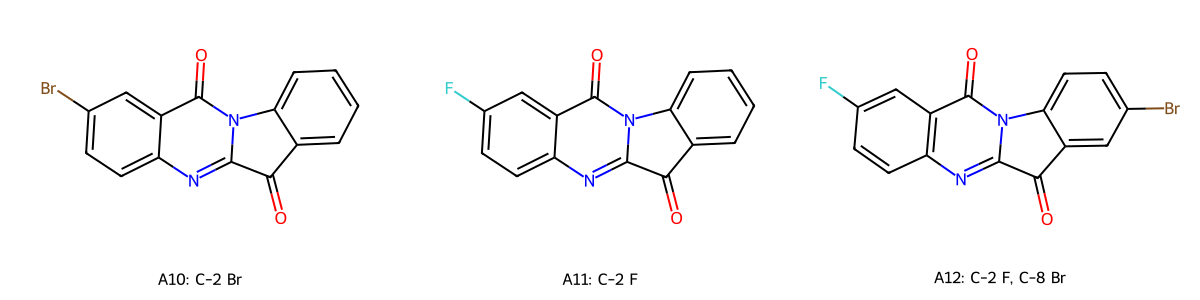

Three references generated; automated checks passed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
from pathlib import Path
from datetime import datetime, timezone
import shutil
import pandas as pd
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display
from google.colab import files

# These indices apply ONLY to this exact SMILES.
PARENT_SMILES = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
SITE_INDICES = {"C-2": 14, "C-8": 4}

parent = Chem.MolFromSmiles(PARENT_SMILES)
assert parent is not None
assert Chem.MolToInchiKey(parent) == \
    "VQQVWGVXDIPORV-UHFFFAOYSA-N"

definitions = [
    ("A10", [("C-2", "Br")], "C15H7BrN2O2", "S8-S9"),
    ("A11", [("C-2", "F")], "C15H7FN2O2", "S9"),
    ("A12", [("C-2", "F"), ("C-8", "Br")], "C15H6BrFN2O2", "S9"),
]

rows, molecules, legends = [], [], []

for compound_id, modifications, expected_formula, pages in definitions:
    editable = Chem.RWMol(parent)

    for site_name, fragment_smiles in modifications:
        site_index = SITE_INDICES[site_name]
        site = parent.GetAtomWithIdx(site_index)

        assert site.GetSymbol() == "C"
        assert site.GetIsAromatic()
        assert site.GetTotalNumHs() == 1

        # These three references use single-atom halogen fragments.
        fragment = Chem.MolFromSmiles(fragment_smiles)
        assert fragment is not None and fragment.GetNumAtoms() == 1

        added_index = editable.AddAtom(
            Chem.Atom(fragment.GetAtomWithIdx(0))
        )
        editable.AddBond(
            site_index, added_index, Chem.BondType.SINGLE
        )

    analog = editable.GetMol()
    Chem.SanitizeMol(analog)

    formula = rdMolDescriptors.CalcMolFormula(analog)
    assert formula == expected_formula, f"{compound_id}: formula mismatch"
    assert analog.HasSubstructMatch(parent)
    assert len(Chem.GetMolFrags(analog)) == 1
    assert Chem.GetFormalCharge(analog) == 0

    rows.append({
        "Reference_ID": f"Gao2021_{compound_id}",
        "Source_compound_ID": compound_id,
        "SMILES": Chem.MolToSmiles(analog, canonical=True),
        "InChIKey": Chem.MolToInchiKey(analog),
        "Modified_site": "; ".join(s for s, f in modifications),
        "Substituent": "; ".join(f for s, f in modifications),
        "Molecular_formula": formula,
        "Source_DOI": "10.3390/biomedicines9111527",
        "Source_location": f"Figure 1B; supplement {pages}",
        "Status": "Published reference reconstruction",
        "Automated_checks": "PASS",
        "RDKit_version": rdBase.rdkitVersion,
    })

    molecules.append(analog)
    legends.append(
        compound_id + ": " +
        ", ".join(f"{s} {f}" for s, f in modifications)
    )

table = pd.DataFrame(rows)
assert table["SMILES"].is_unique

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
out = Path("Gao2021_A10_A12_runs") / run_id
out.mkdir(parents=True, exist_ok=False)

table.to_csv(out / "A10_A12_reference_batch.csv", index=False)

grid = Draw.MolsToGridImage(
    molecules,
    legends=legends,
    molsPerRow=3,
    subImgSize=(400, 300),
    useSVG=False,
    returnPNG=False
)
grid.save(out / "A10_A12_structure_grid.png")

display(table)
display(grid)
print("Three references generated; automated checks passed.")

archive = shutil.make_archive(
    f"/content/Gao2021_A10_A12_{run_id}",
    "zip",
    root_dir=str(out)
)
files.download(archive)

In [14]:
from pathlib import Path
import pandas as pd
from google.colab import files

# Use the exact runs you shared and we reviewed.
c8_path = Path(
    "Gao2021_C8_reference_runs/20261020T040957461912Z/"
    "reference_library_clean.csv"
)
c2_path = Path(
    "Gao2021_A10_A12_runs/20261020T041142685179Z/"
    "A10_A12_reference_batch.csv"
)

assert c8_path.exists(), f"Missing file: {c8_path}"
assert c2_path.exists(), f"Missing file: {c2_path}"

c8 = pd.read_csv(c8_path)
c2 = pd.read_csv(c2_path)

# Give both batches the same column names.
c8["Automated_checks"] = c8["Validation_status"]
c8["Status"] = "Published reference reconstruction"

columns = [
    "Reference_ID",
    "Source_compound_ID",
    "SMILES",
    "InChIKey",
    "Modified_site",
    "Substituent",
    "Molecular_formula",
    "Source_DOI",
    "Source_location",
    "Status",
    "Automated_checks",
    "RDKit_version",
]

references = pd.concat(
    [c8[columns], c2[columns]],
    ignore_index=True
)

expected_ids = {f"Gao2021_A{i}" for i in range(1, 13)}

assert set(references["Reference_ID"]) == expected_ids
assert len(references) == 12
assert references["Reference_ID"].is_unique
assert references["SMILES"].is_unique
assert references["InChIKey"].is_unique
assert references["Automated_checks"].eq("PASS").all()
assert references[columns].notna().all().all()

references["_order"] = (
    references["Source_compound_ID"].str.extract(r"(\d+)")[0].astype(int)
)
references = references.sort_values("_order").drop(columns="_order")

filename = "Gao2021_reference_library_A1_A12.csv"
references.to_csv(filename, index=False)

display(references)
print("Consolidation passed: 12 unique published reference analogs.")
print("Parent tryptanthrin remains in the separate parent-reference file.")

files.download(filename)

,Reference_ID,Source_compound_ID,SMILES,InChIKey,Modified_site,Substituent,Molecular_formula,Source_DOI,Source_location,Status,Automated_checks,RDKit_version
0,Gao2021_A1,A1,O=C1c2cc(Br)ccc2-n2c1nc1ccccc1c2=O,INPHXCCBDRGBRF-UHFFFAOYSA-N,C-8,Br,C15H7BrN2O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
1,Gao2021_A2,A2,O=C1c2cc(I)ccc2-n2c1nc1ccccc1c2=O,BBGAOZGNPWPXNH-UHFFFAOYSA-N,C-8,I,C15H7IN2O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
2,Gao2021_A3,A3,O=C1c2cc(Cl)ccc2-n2c1nc1ccccc1c2=O,WUCIHZUJKXUKMW-UHFFFAOYSA-N,C-8,Cl,C15H7ClN2O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
3,Gao2021_A4,A4,O=C1c2cc(F)ccc2-n2c1nc1ccccc1c2=O,UXBGZQXHNVNPFT-UHFFFAOYSA-N,C-8,F,C15H7FN2O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
4,Gao2021_A5,A5,Cc1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,DSZRZFCUYHAAAE-UHFFFAOYSA-N,C-8,CH3,C16H10N2O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
5,Gao2021_A6,A6,O=C1c2cc([N+](=O)[O-])ccc2-n2c1nc1ccccc1c2=O,UFMQJYHLIUACCG-UHFFFAOYSA-N,C-8,NO2,C15H7N3O4,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
6,Gao2021_A7,A7,Nc1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,GXWUJSVZVDFGGN-UHFFFAOYSA-N,C-8,NH2,C15H9N3O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
7,Gao2021_A8,A8,O=C1c2cc(C(F)(F)F)ccc2-n2c1nc1ccccc1c2=O,GAARSXQWGXXCAD-UHFFFAOYSA-N,C-8,CF3,C16H7F3N2O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
8,Gao2021_A9,A9,CN(C)c1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,QKFGOBMYCBMJCZ-UHFFFAOYSA-N,C-8,N(CH3)2,C17H13N3O2,10.3390/biomedicines9111527,Figure 1B; supplementary chemical names,Published reference reconstruction,PASS,2026.09.1
9,Gao2021_A10,A10,O=C1c2ccccc2-n2c1nc1ccc(Br)cc1c2=O,CPZULIGVBXZLGC-UHFFFAOYSA-N,C-2,Br,C15H7BrN2O2,10.3390/biomedicines9111527,Figure 1B; supplement S8-S9,Published reference reconstruction,PASS,2026.09.1


Consolidation passed: 12 unique published reference analogs.
Parent tryptanthrin remains in the separate parent-reference file.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>